# Anomaly Detection

***
## outlier - extreme values
## anomaly - Suspicious/unusual datapoint

## all outliers are not anomaly
***

### 1. FRAUD DETECTION
### 2. MANUFACTURING
### 3. MEDICAL DIAGNOSIS
### 4. CYBER SEQURITY
### 5. BOT DETECTION

In [1]:
# TECHNIQUES:

    ## DBSCAN
    ## ISOLATION FOREST
    ## LOF - LOCAL OUTLIER FACTOR

In [2]:
# DBSCAN FOR ANOMALY DETECTIOIN

# E- neighborhood samples < min samples + disconnected from core points => anomaly/Noise

In [25]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
X , y = make_moons(
    n_samples = 500,
    noise = 0.1,
    random_state = 42
)

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

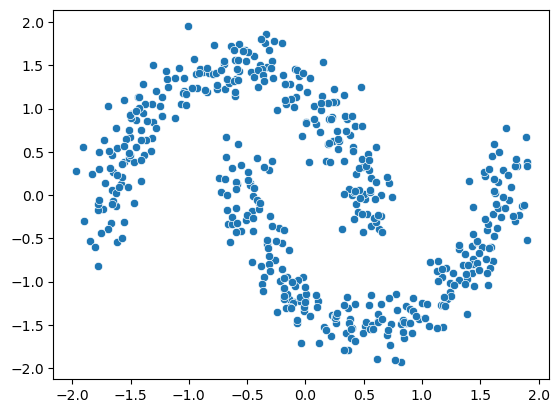

In [6]:
# vizualization
sns.scatterplot(
    x = X_scaled[:,0],
    y = X_scaled[:,1]
)

In [8]:
# min samples :
        # if too low - noise becomes normal samples
        # if too high - mormal data becomes noise

        # BEST PRACTICE : 
            # min_sample = 2*features

# epsillion - neighborhood size

        # low dimension (< 10 features) : 0.5 - 1
        # medium dim (10 - 20 features) : 1-2
        # high dime (> 20) : >2

In [15]:
dbscan = DBSCAN(
    eps=0.18,
    min_samples = 5
)

labels = dbscan.fit_predict(X_scaled)

<Axes: >

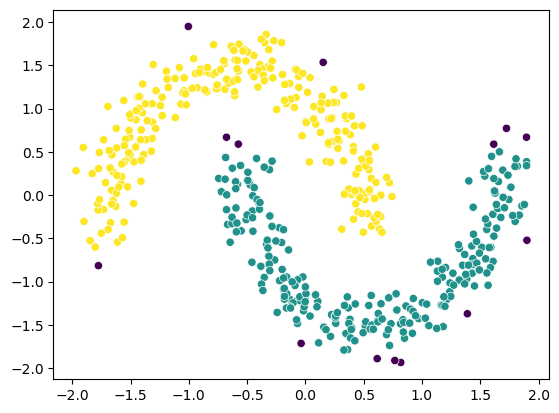

In [16]:
sns.scatterplot(
    x = X_scaled[:,0],
    y = X_scaled[:,1],
    c=labels
)

***

# ISOLATION FOREST - ENSEMBEL LEARNING TECHNIQUE
***

In [18]:
# ALGO ASSUMES THAT :
    # OUTLIERS LIE IN SPARSE SPACE => LESS NO. OF SPLITS REQ TO SEPARATE THEM

In [19]:
# STEPS:

        # 1. ISOLATION TREES => BUILD MULTIPLE RANDOM DT
                            # LEAF NODE (SINGLE SAMPLE)
        # 2. CALC. PATH LENGTH => (root -> leaf/samples)
                            # PATH LENGTH LESS => OUTLIER (HIGH CHANCES)
                            # PATH LENGTH MORE => NORAMAL (HIGH CHANCES)

        # CREATE MULTIPLE TREES =>CALCULATE AVG. PATH LENGTH [ANOMALY SCORE]

In [22]:
# Anomaly_score(x) = 2^ -(E(h(x)))/c(n)

# x = one sample
# n = size of data set
# E(h(x)) = avg path length of x in all trees
# c(n) = mean path length  of all points

# AS(x) =>  AROUND 1 = OUTLIER
      # => AROUND 0 = NORMAL

In [26]:
df = pd.read_csv("thyroid_dataset.csv")

In [28]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [44]:
X = df.drop("Outlier_label", axis=1)
y = df["Outlier_label"]

In [45]:
X_scaled = scaler.fit_transform(X)

In [46]:
from sklearn.ensemble import IsolationForest

clf = IsolationForest(
    n_estimators=200,
    contamination=0.036,
    random_state = 42
)

In [47]:
labels = clf.fit_predict(X_scaled)

In [48]:
labels

array([ 1,  1, -1, ...,  1,  1,  1])

In [49]:
# vizualize

from sklearn.decomposition import PCA

pca = PCA(n_components =2)
X_pca = pca.fit_transform(X_scaled)

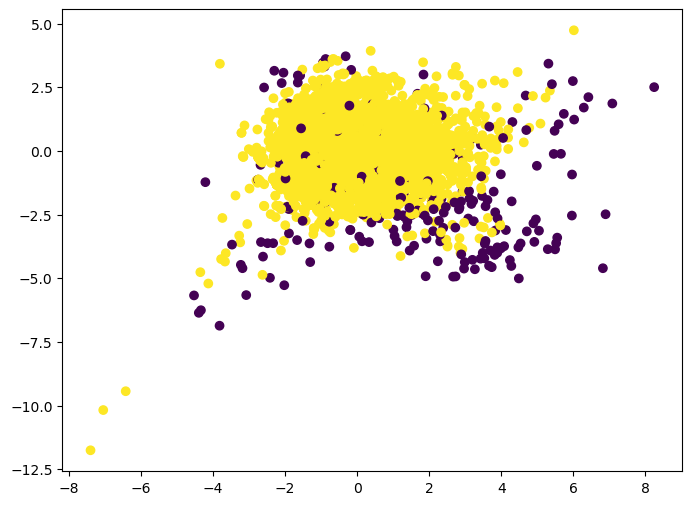

In [50]:
plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0],X_pca[:,1], c= labels)

In [51]:
import numpy as np

outliers = np.sum(labels ==-1)
normal = np.sum(labels ==1)

print(outliers)
print(normal)

249
6667


In [52]:
# ambiguity due to PCA plot 

***
# LOF - LOCAL OUTLIER FACTOR
***

In [65]:
# helps to identify Local outliers : outliers that are near to a cluster
                            # due to which most algorithm miss these outliers

# choose k(neighbor)
# new point : calculate nearest distance to k points
# calculate further distances of k points to its nearest neighbors


# calculate LOF = Neighbor_density / Point_density
# based on this LOF score determine whether it is a local outlier or not

In [54]:
from sklearn.neighbors import LocalOutlierFactor

In [60]:
neigh = LocalOutlierFactor(contamination=0.036)

In [61]:
labels = neigh.fit_predict(X_scaled)

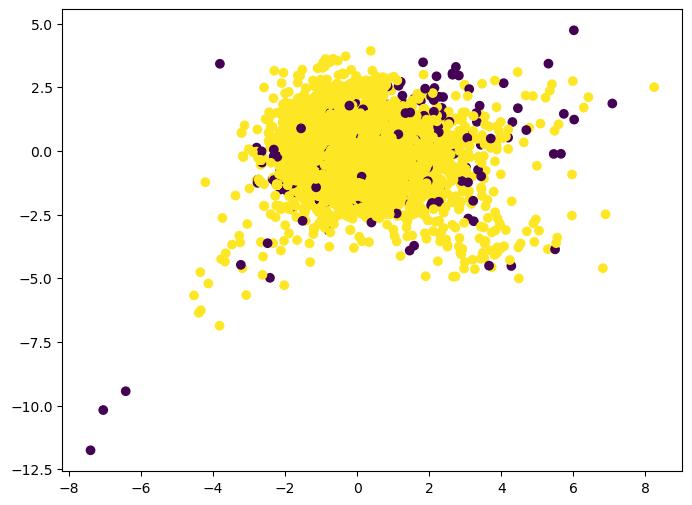

In [62]:
plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0],X_pca[:,1], c= labels)

In [63]:
outliers = np.sum(labels ==-1)
normal = np.sum(labels ==1)

print(outliers)
print(normal)

249
6667
